<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Midterm, Part A: hyperparameter search for the denoising autoencoder, on a Colab L4 GPU</p>
<p><a href="https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_experiments.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"></a></p>
<p>The search of assignment section A2, built like tutoring/session01/04_tensorboard.ipynb: a train_run helper, one TensorBoard folder per run, and read_scalars / plot_metric to compare runs. The model, the data and the k-NN come from the repository; nothing in its .py files is changed here.</p>
<p>The notebook asks Colab for an L4 GPU runtime. If it opens on another runtime, choose Runtime, then Change runtime type, then L4 GPU.</p>
<p>The search is staged. Each stage changes one or two hyperparameters, starts from the winner of the previous stage, and keeps the run with the best validation k-NN top-1 accuracy:</p>
<ol>
<li>Stage 1: activation {ReLU, GELU} × optimizer {Adam, AdamW}, 4 runs.</li>
<li>Stage 2: noise type {gaussian, mask, salt_pepper} × noise level {0.05, 0.1, 0.25, 0.5, 0.75}, 15 runs.</li>
<li>Stage 3: latent_dim {32, 64, 128, 256, 512}, 5 runs.</li>
<li>Stage 4: batch size {64, 128, 256, 512}, 4 runs.</li>
<li>Stage 5: learning rate {1e-4, 3e-4, 1e-3, 3e-3, 1e-2}, 5 runs.</li>
<li>Stage 6: one 50-epoch run of the winner, to choose the number of epochs.</li>
</ol>
<p>Rules of the search:</p>
<ul>
<li>Stages 1 to 5 use the proxy setting: 8 epochs per run.</li>
<li>Selection is always by val k-NN top-1 (k = 20, cosine), never by reconstruction error. The test set is not used.</li>
<li>During the search the k-NN memory bank is a class-balanced 20,000 of the 90,000 training images, to make each epoch faster. Final models use all 90,000.</li>
<li>Every run is saved on Drive. A loop that was cut off skips the runs that already finished, and an unfinished run continues from its last.ckpt.</li>
<li>The winner of every stage is saved in winners.json on Drive, so a new runtime continues from the last finished stage.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>מטלת אמצע, חלק A: חיפוש היפר-פרמטרים ל-denoising autoencoder, על GPU מסוג L4 ב-Colab</p>
<p>החיפוש של סעיף A2 במטלה, בנוי כמו tutoring/session01/04_tensorboard.ipynb: פונקציית train_run, תיקיית TensorBoard אחת לכל ריצה, ו-read_scalars / plot_metric כדי להשוות בין ריצות. המודל, הדאטה וה-k-NN מגיעים מה-repository; שום קובץ ‎.py שלו לא משתנה כאן.</p>
<p>המחברת מבקשת מ-Colab סביבת ריצה עם GPU מסוג L4. אם היא נפתחת על סביבה אחרת, בוחרים Runtime, אחר כך Change runtime type, אחר כך L4 GPU.</p>
<p>החיפוש מחולק לשלבים. כל שלב משנה היפר-פרמטר אחד או שניים, מתחיל מהמנצח של השלב הקודם, ושומר את הריצה עם דיוק ה-k-NN top-1 הכי טוב על ה-validation:</p>
<ol>
<li>שלב 1: activation {ReLU, GELU} × optimizer {Adam, AdamW}, ‏4 ריצות.</li>
<li>שלב 2: סוג רעש {gaussian, mask, salt_pepper} × עוצמת רעש {0.05, 0.1, 0.25, 0.5, 0.75}, ‏15 ריצות.</li>
<li>שלב 3: ‏latent_dim {32, 64, 128, 256, 512}, ‏5 ריצות.</li>
<li>שלב 4: ‏batch size {64, 128, 256, 512}, ‏4 ריצות.</li>
<li>שלב 5: ‏learning rate {1e-4, 3e-4, 1e-3, 3e-3, 1e-2}, ‏5 ריצות.</li>
<li>שלב 6: ריצה אחת של 50 epochs של המנצח, כדי לבחור את מספר ה-epochs.</li>
</ol>
<p>כללי החיפוש:</p>
<ul>
<li>שלבים 1 עד 5 רצים ב-proxy setting: ‏8 epochs לכל ריצה.</li>
<li>הבחירה תמיד לפי val k-NN top-1 (‏k = 20, ‏cosine), אף פעם לא לפי שגיאת השחזור. ה-test set לא בשימוש.</li>
<li>בזמן החיפוש ה-memory bank של ה-k-NN הוא 20,000 תמונות מאוזנות בין המחלקות, מתוך 90,000 תמונות האימון, כדי שכל epoch יהיה מהיר יותר. המודלים הסופיים משתמשים בכל ה-90,000.</li>
<li>כל ריצה נשמרת ב-Drive. לולאה שנקטעה מדלגת על הריצות שכבר הסתיימו, וריצה שלא הסתיימה ממשיכה מה-last.ckpt שלה.</li>
<li>המנצח של כל שלב נשמר ב-winners.json ב-Drive, כך שסביבת ריצה חדשה ממשיכה מהשלב האחרון שהסתיים.</li>
</ul>
<hr>
</div>

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 1: clone the repository</p>
<ul>
<li>Downloads the code from GitHub into /content and moves into it. Run it once per runtime.</li>
<li>If the repository is already on this runtime, git clone fails; run the next cell instead.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 1: שכפול ה-repository</p>
<ul>
<li>מוריד את הקוד מ-GitHub לתיקייה ‎/content ונכנס אליו. מריצים פעם אחת בכל סביבת ריצה.</li>
<li>אם ה-repository כבר נמצא בסביבת הריצה, git clone נכשל; במקרה כזה מריצים את התא הבא.</li>
</ul>
</div>

In [1]:
import os

REPO_DIR = "/content/Representation-Learning-Midterm-DAE-SimCLR"
!git clone https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR.git
os.chdir(REPO_DIR)
!pwd

Cloning into 'Representation-Learning-Midterm-DAE-SimCLR'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 30 (delta 13), reused 27 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 24.68 KiB | 1.07 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/Representation-Learning-Midterm-DAE-SimCLR


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 1 (again): pull the latest code</p>
<ul>
<li>Instead of the clone cell, when the repository is already on this runtime: git pull brings the latest commits.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 1 (שוב): משיכת הקוד העדכני</p>
<ul>
<li>במקום תא השכפול, כשה-repository כבר נמצא בסביבת הריצה: ‏git pull מביא את ה-commits האחרונים.</li>
</ul>
</div>

In [2]:
import os

REPO_DIR = "/content/Representation-Learning-Midterm-DAE-SimCLR"
os.chdir(REPO_DIR)
!git pull
!pwd

Already up to date.
/content/Representation-Learning-Midterm-DAE-SimCLR


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 2: install the requirements and check the GPU</p>
<ul>
<li>Installs requirements.txt (pytorch-lightning, torchmetrics, tensorboard, datasets and the rest).</li>
<li>Stops with an error if there is no GPU, and prints its name. It should be NVIDIA L4.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 2: התקנת החבילות ובדיקת ה-GPU</p>
<ul>
<li>מתקין את requirements.txt (‏pytorch-lightning, ‏torchmetrics, ‏tensorboard, ‏datasets והשאר).</li>
<li>נעצר עם שגיאה אם אין GPU, ומדפיס את השם שלו. הוא אמור להיות NVIDIA L4.</li>
</ul>
</div>

In [3]:
%pip install -q -r requirements.txt

import torch
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → L4 GPU, then rerun this cell."
print(torch.cuda.get_device_name(0))

NVIDIA A100-SXM4-40GB


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 3: Google Drive</p>
<ul>
<li>Mounts Google Drive. LOG_DIR is the folder of the search: every run, its checkpoints and winners.json.</li>
<li>It is apart from the folders of colab_train.ipynb, so the search never touches the real runs.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 3: ‏Google Drive</p>
<ul>
<li>מחבר את Google Drive. ‏LOG_DIR היא התיקייה של החיפוש: כל הריצות, ה-checkpoints שלהן ו-winners.json.</li>
<li>היא נפרדת מהתיקיות של colab_train.ipynb, כך שהחיפוש אף פעם לא נוגע בריצות האמיתיות.</li>
</ul>
</div>

In [4]:
from google.colab import drive

drive.mount("/content/drive")
LOG_DIR = "/content/drive/MyDrive/rl_midterm_experiments/search"
os.makedirs(LOG_DIR, exist_ok=True)
print(LOG_DIR)

Mounted at /content/drive
/content/drive/MyDrive/rl_midterm_experiments/search


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 4: import the repository code</p>
<ul>
<li>Imports the repository modules as they are: config, ImageDataModule, DenoisingAutoEncoder and the callbacks (KNNCallback and the rest).</li>
<li>SEARCH_EPOCHS = 8 and SEARCH_BANK_SIZE = 20,000 are the proxy setting of the search.</li>
<li>get_dm builds the Tiny-ImageNet datamodule once per batch size and reuses it. The first call downloads the dataset (about 160 MB) into the repository's dataset folder.</li>
<li>The splits come from config.SEED, so every run sees the same 90,000 training and 10,000 validation images.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 4: ייבוא הקוד מה-repository</p>
<ul>
<li>מייבא את המודולים של ה-repository כמו שהם: ‏config, ‏ImageDataModule, ‏DenoisingAutoEncoder וה-callbacks (‏KNNCallback והשאר).</li>
<li>‏SEARCH_EPOCHS = 8 ו-SEARCH_BANK_SIZE = 20,000 הם ה-proxy setting של החיפוש.</li>
<li>‏get_dm בונה את ה-datamodule של Tiny-ImageNet פעם אחת לכל batch size ומשתמש בו שוב. הקריאה הראשונה מורידה את הדאטה-סט (כ-160 MB) לתיקיית dataset של ה-repository.</li>
<li>הפיצולים נקבעים לפי config.SEED, כך שכל ריצה רואה את אותן 90,000 תמונות אימון ו-10,000 תמונות validation.</li>
</ul>
</div>

In [5]:
import json
import logging
import sys
import time
import warnings

import matplotlib.pyplot as plt
import pytorch_lightning as pl
import torch
from pytorch_lightning.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from torch import nn, optim

sys.path.insert(0, REPO_DIR)
import config
from callbacks import ColabProgressBar, EpochMetricsCallback, KNNCallback
from datamodule import ImageDataModule
from model import DenoisingAutoEncoder

torch.set_float32_matmul_precision("medium")
warnings.filterwarnings("ignore", ".*does not have many workers.*")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

SEARCH_EPOCHS = 8  # proxy setting: every run of stages 1-5
SEARCH_BANK_SIZE = 20000  # class-balanced k-NN memory bank during the search (100 per class)
NUM_WORKERS = min(8, os.cpu_count() or 2)  # an L4 runtime has more CPU cores than config.NUM_WORKERS = 2 assumes

_datamodules = {}


def get_dm(batch_size):
    """The Tiny-ImageNet datamodule for this batch size, built once and reused."""
    if batch_size not in _datamodules:
        dm = ImageDataModule(
            data_dir=config.DATA_DIR,
            batch_size=batch_size,
            num_workers=NUM_WORKERS,
            dataset_name="TinyImageNet",
            label_fraction=1.0,  # the DAE uses every training image and no labels
            seed=config.SEED,
        )
        dm.prepare_data()
        dm.setup("fit")
        _datamodules[batch_size] = dm
    return _datamodules[batch_size]


print("workers:", NUM_WORKERS, "| train images:", len(get_dm(256).train_ds), "| val images:", len(get_dm(256).val_ds))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

data/train-00000-of-00001-1359597a978bc4(…): reconstructing file:   0%|          |  0.00B /  146MB            

data/train-00000-of-00001-1359597a978bc4(…): downloading bytes:           |  0.00B            

data/valid-00000-of-00001-70d52db3c749a9(…): reconstructing file:   0%|          |  0.00B / 14.6MB            

data/valid-00000-of-00001-70d52db3c749a9(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating valid split:   0%|          | 0/10000 [00:00<?, ? examples/s]

workers: 8 | train images: 90000 | val images: 10000


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 5: SearchDAE, the repository DAE with an activation and an optimizer to choose</p>
<ul>
<li>Like TrainAccNN(LoggedNN) in notebook 04: a subclass that adds what stage 1 needs, without changing model.py.</li>
<li>activation="gelu" swaps every nn.ReLU in the encoder and the decoder for nn.GELU. GELU has no weights, so the initial weights are the same for both activations.</li>
<li>optimizer="adamw" overrides configure_optimizers with AdamW and weight_decay 0.01. "adam" keeps the repository's Adam.</li>
<li>batch_size is not used by the model. It is an argument only so that save_hyperparameters writes it to hparams.yaml with all the other settings of the run.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 5: ‏SearchDAE, ה-DAE של ה-repository עם activation ו-optimizer לבחירה</p>
<ul>
<li>כמו TrainAccNN(LoggedNN) במחברת 04: מחלקה יורשת שמוסיפה את מה ששלב 1 צריך, בלי לשנות את model.py.</li>
<li>‏activation="gelu" מחליף כל nn.ReLU ב-encoder וב-decoder ב-nn.GELU. ל-GELU אין משקלים, ולכן המשקלים ההתחלתיים זהים בשתי ה-activations.</li>
<li>‏optimizer="adamw" דורס את configure_optimizers עם AdamW ו-weight_decay 0.01. ‏"adam" משאיר את ה-Adam של ה-repository.</li>
<li>‏batch_size לא משמש את המודל. הוא ארגומנט רק כדי ש-save_hyperparameters יכתוב אותו ל-hparams.yaml עם כל שאר ההגדרות של הריצה.</li>
</ul>
</div>

In [6]:
class SearchDAE(DenoisingAutoEncoder):
    def __init__(self, learning_rate, latent_dim, noise_type, noise_level,
                 activation="relu", optimizer="adam", weight_decay=0.01, batch_size=256):
        super().__init__(learning_rate, latent_dim, noise_type, noise_level)
        self.save_hyperparameters()  # all the arguments above -> self.hparams and hparams.yaml
        if activation == "gelu":
            for layers in (self.encoder, self.decoder):
                for i, layer in enumerate(layers):
                    if isinstance(layer, nn.ReLU):
                        layers[i] = nn.GELU()

    def configure_optimizers(self):
        if self.hparams.optimizer == "adamw":
            return optim.AdamW(self.parameters(), lr=self.hparams.learning_rate, weight_decay=self.hparams.weight_decay)
        return super().configure_optimizers()  # Adam, as in model.py


print(SearchDAE(1e-3, 64, "gaussian", 0.25, activation="gelu").encoder)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (1): GELU(approximate='none')
  (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (3): GELU(approximate='none')
  (4): Flatten(start_dim=1, end_dim=-1)
  (5): Linear(in_features=16384, out_features=64, bias=True)
)


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 6: train_run, one run of the search</p>
<ul>
<li>train_run(model, stage, version, batch_size, epochs) logs to LOG_DIR/stage/version, as train_run does in notebook 04.</li>
<li>The Trainer uses precision 16-mixed, KNNCallback with the 20,000-image bank (val k-NN after every epoch), EpochMetricsCallback (one point per epoch under epoch/...), and ModelCheckpoint on val_knn_top1 with save_last=True.</li>
<li>fit(..., ckpt_path="last") continues a run that was cut off from its last.ckpt.</li>
<li>A finished run writes done.json in its folder. If done.json is there, train_run skips the run, so a loop that stopped continues from the first unfinished run.</li>
<li>run_trial(stage, version, settings) fixes the seed, builds SearchDAE from a settings dictionary and calls train_run.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 6: ‏train_run, ריצה אחת של החיפוש</p>
<ul>
<li>‏train_run(model, stage, version, batch_size, epochs) כותב לוגים ל-LOG_DIR/stage/version, כמו train_run במחברת 04.</li>
<li>ה-Trainer משתמש ב-precision ‏16-mixed, ב-KNNCallback עם bank של 20,000 תמונות (‏val k-NN אחרי כל epoch), ב-EpochMetricsCallback (נקודה אחת לכל epoch תחת epoch/...), וב-ModelCheckpoint על val_knn_top1 עם save_last=True.</li>
<li>‏fit(..., ckpt_path="last") ממשיך ריצה שנקטעה מה-last.ckpt שלה.</li>
<li>ריצה שהסתיימה כותבת done.json בתיקייה שלה. אם done.json קיים, ‏train_run מדלג על הריצה, כך שלולאה שנעצרה ממשיכה מהריצה הראשונה שלא הסתיימה.</li>
<li>‏run_trial(stage, version, settings) קובע את ה-seed, בונה SearchDAE ממילון הגדרות וקורא ל-train_run.</li>
</ul>
</div>

In [7]:
def train_run(model, stage, version, batch_size, epochs=SEARCH_EPOCHS):
    """Train one model and log it to LOG_DIR/stage/version. Skips a run that already finished."""
    run_dir = os.path.join(LOG_DIR, stage, version)
    done_file = os.path.join(run_dir, "done.json")
    if os.path.exists(done_file):
        with open(done_file) as f:
            result = json.load(f)
        print(f"skip {stage}/{version}: already finished, val k-NN top-1 {result['val_knn_top1']:.4f}")
        return result

    start = time.time()
    logger = TensorBoardLogger(LOG_DIR, name=stage, version=version, default_hp_metric=False)
    checkpoint = ModelCheckpoint(
        dirpath=os.path.join(run_dir, "checkpoints"), monitor="val_knn_top1", mode="max", save_last=True
    )
    trainer = pl.Trainer(
        logger=logger,
        accelerator="gpu",
        devices=1,
        precision="16-mixed",
        max_epochs=epochs,
        log_every_n_steps=10,
        callbacks=[
            KNNCallback(k=config.KNN_K, bank_size=SEARCH_BANK_SIZE),
            EpochMetricsCallback(),
            checkpoint,
            ColabProgressBar(refresh_rate=50),
        ],
    )
    trainer.fit(model, get_dm(batch_size), ckpt_path="last")  # continues from last.ckpt if the run was cut off

    result = {
        "val_knn_top1": float(checkpoint.best_model_score),
        "epochs": epochs,
        "minutes": round((time.time() - start) / 60, 1),
        "settings": dict(model.hparams),
    }
    with open(done_file, "w") as f:
        json.dump(result, f, indent=1)
    print(f"done {stage}/{version}: val k-NN top-1 {result['val_knn_top1']:.4f} in {result['minutes']} min")
    return result


def run_trial(stage, version, settings, epochs=SEARCH_EPOCHS):
    """Same seed for every run, so the runs differ only in their settings."""
    pl.seed_everything(config.TRAIN_SEED)
    model = SearchDAE(**settings)
    return train_run(model, stage, version, settings["batch_size"], epochs)

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 7: read the logs back, compare runs, pick the winner</p>
<ul>
<li>read_scalars(stage, version, tag) reads one logged value of one run from disk with EventAccumulator, as in notebook 04. The default tag is epoch/val_knn_top1, whose step is the epoch (0 = the first epoch).</li>
<li>plot_metric(stage, tag, versions) draws several runs on one chart, against the epoch.</li>
<li>best_of(stage) reads the best val_knn_top1 of every finished run of the stage, prints them from best to worst, saves the winner in winners.json on Drive and returns its settings.</li>
<li>load_winner(stage) returns the settings saved for that stage, so the next stage starts from them, also on a new runtime.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 7: קריאת הלוגים, השוואה בין ריצות ובחירת המנצח</p>
<ul>
<li>‏read_scalars(stage, version, tag) קורא מהדיסק ערך אחד שנרשם בריצה אחת, עם EventAccumulator, כמו במחברת 04. ה-tag ברירת המחדל הוא epoch/val_knn_top1, שה-step שלו הוא ה-epoch (‏0 = ה-epoch הראשון).</li>
<li>‏plot_metric(stage, tag, versions) מצייר כמה ריצות על גרף אחד, מול ה-epoch.</li>
<li>‏best_of(stage) קורא את ה-val_knn_top1 הכי טוב של כל ריצה שהסתיימה בשלב, מדפיס אותן מהטובה לגרועה, שומר את המנצח ב-winners.json ב-Drive ומחזיר את ההגדרות שלו.</li>
<li>‏load_winner(stage) מחזיר את ההגדרות ששמורות לשלב הזה, כך שהשלב הבא מתחיל מהן, גם בסביבת ריצה חדשה.</li>
</ul>
</div>

In [8]:
WINNERS_FILE = os.path.join(LOG_DIR, "winners.json")


def read_scalars(stage, version, tag="epoch/val_knn_top1"):
    """[(step, value), ...] for one tag of one run. For epoch/... tags the step is the epoch, from 0."""
    events = EventAccumulator(os.path.join(LOG_DIR, stage, version), size_guidance={"scalars": 0})
    events.Reload()
    if tag not in events.Tags()["scalars"]:
        return []
    by_step = {e.step: e.value for e in events.Scalars(tag)}  # a resumed run can log a step twice: keep the last
    return sorted(by_step.items())


def finished_versions(stage):
    stage_dir = os.path.join(LOG_DIR, stage)
    if not os.path.isdir(stage_dir):
        return []
    return sorted(v for v in os.listdir(stage_dir) if os.path.exists(os.path.join(stage_dir, v, "done.json")))


def plot_metric(stage, tag="epoch/val_knn_top1", versions=None):
    """One tag for several runs of a stage, against the epoch."""
    plt.figure(figsize=(7, 3.5))
    for version in versions or finished_versions(stage):
        points = read_scalars(stage, version, tag)
        if points:
            steps, values = zip(*points)
            plt.plot([s + 1 for s in steps], values, marker=".", label=version)
    plt.xlabel("epoch")
    plt.ylabel(tag)
    plt.title(stage)
    plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.grid(alpha=0.3)
    plt.show()


def load_winners():
    if os.path.exists(WINNERS_FILE):
        with open(WINNERS_FILE) as f:
            return json.load(f)
    return {}


def best_of(stage):
    """Best val k-NN top-1 of every finished run of the stage. Saves and returns the winner's settings."""
    scores = {}
    for version in finished_versions(stage):
        points = read_scalars(stage, version)
        if points:
            scores[version] = max(value for _, value in points)
        else:  # no per-epoch points in the log: fall back to the checkpoint's score
            with open(os.path.join(LOG_DIR, stage, version, "done.json")) as f:
                scores[version] = json.load(f)["val_knn_top1"]
    assert scores, f"No finished run in {stage} yet."
    for version, score in sorted(scores.items(), key=lambda item: -item[1]):
        print(f"  {version:<24} val k-NN top-1 {score:.4f}")
    winner = max(scores, key=scores.get)
    with open(os.path.join(LOG_DIR, stage, winner, "done.json")) as f:
        settings = json.load(f)["settings"]
    winners = load_winners()
    winners[stage] = {"version": winner, "val_knn_top1": scores[winner], "settings": settings}
    with open(WINNERS_FILE, "w") as f:
        json.dump(winners, f, indent=1)
    print(f"winner of {stage}: {winner} ({scores[winner]:.4f})")
    return settings


def load_winner(stage):
    winners = load_winners()
    assert stage in winners, f"No winner saved for {stage}. Run best_of({stage!r}) first."
    return winners[stage]["settings"]


print("winners so far:", {stage: w["version"] for stage, w in load_winners().items()})

winners so far: {}


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 8: TensorBoard</p>
<ul>
<li>Shows every run of the search, grouped by stage. Run it before the stages; press its refresh button to see new points.</li>
<li>epoch/val_knn_top1 and epoch/val_loss compare the runs per epoch; IMAGES shows clean, noisy and reconstructed images.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 8: ‏TensorBoard</p>
<ul>
<li>מציג את כל הריצות של החיפוש, מקובצות לפי שלב. מריצים אותו לפני השלבים; לוחצים על כפתור הרענון שלו כדי לראות נקודות חדשות.</li>
<li>‏epoch/val_knn_top1 ו-epoch/val_loss משווים בין הריצות לפי epoch; ‏IMAGES מציג תמונות נקיות, רועשות ומשוחזרות.</li>
</ul>
</div>

In [9]:
%load_ext tensorboard
%tensorboard --logdir "{LOG_DIR}"

<IPython.core.display.Javascript object>

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 1: activation × optimizer (4 runs)</p>
<ul>
<li>Starts from the repository defaults: gaussian noise 0.25, latent_dim 64, lr 1e-3, batch size 256.</li>
<li>Tries ReLU and GELU with Adam and with AdamW (weight_decay 0.01). Version names: relu_adam, relu_adamw, gelu_adam, gelu_adamw.</li>
<li>The winning activation and optimizer are kept for every later stage.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 1: ‏activation × optimizer (‏4 ריצות)</p>
<ul>
<li>מתחיל מברירות המחדל של ה-repository: רעש gaussian ‏0.25, ‏latent_dim 64, ‏lr 1e-3, ‏batch size 256.</li>
<li>בודק ReLU ו-GELU עם Adam ועם AdamW (‏weight_decay 0.01). שמות הגרסאות: relu_adam, ‏relu_adamw, ‏gelu_adam, ‏gelu_adamw.</li>
<li>ה-activation וה-optimizer המנצחים נשארים בכל השלבים הבאים.</li>
</ul>
</div>

In [10]:
BASE = dict(
    activation="relu", optimizer="adam", weight_decay=0.01,
    noise_type="gaussian", noise_level=0.25, latent_dim=64, learning_rate=1e-3, batch_size=256,
)
for activation in ["relu", "gelu"]:
    for optimizer in ["adam", "adamw"]:
        run_trial("stage1", f"{activation}_{optimizer}", {**BASE, "activation": activation, "optimizer": optimizer})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  1.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  1.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 2.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.2 M                                                                                                
Total estimated model params size (MB): 8.609                                                                      
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (53 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage1/gelu_adamw: val k-NN top-1 0.0452 in 2.8 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage1: val k-NN top-1 per epoch, every run of the stage on one chart.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage1: ‏val k-NN top-1 לפי epoch, כל הריצות של השלב על גרף אחד.</p>
</div>

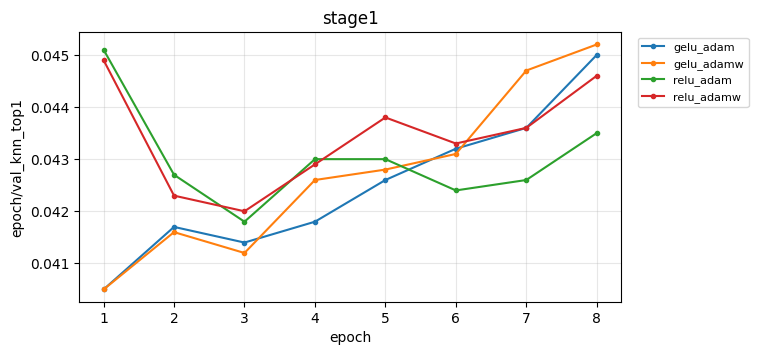

In [11]:
plot_metric("stage1")

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage1: the winner, by val k-NN top-1. It is saved in winners.json, and the next stage starts from it.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage1: המנצח, לפי val k-NN top-1. הוא נשמר ב-winners.json, והשלב הבא מתחיל ממנו.</p>
</div>

In [12]:
best_of("stage1")

  gelu_adamw               val k-NN top-1 0.0452
  relu_adam                val k-NN top-1 0.0451
  gelu_adam                val k-NN top-1 0.0450
  relu_adamw               val k-NN top-1 0.0449
winner of stage1: gelu_adamw (0.0452)


{'learning_rate': 0.001,
 'latent_dim': 64,
 'noise_type': 'gaussian',
 'noise_level': 0.25,
 'activation': 'gelu',
 'optimizer': 'adamw',
 'weight_decay': 0.01,
 'batch_size': 256}

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 2: noise type × noise level (15 runs, in 3 cells)</p>
<ul>
<li>Starts from the stage-1 winner. One cell per noise type, 5 noise levels each: {0.05, 0.1, 0.25, 0.5, 0.75}.</li>
<li>gaussian: the level is the noise std, in units of the per-channel std. mask and salt_pepper: the level is the fraction of pixels corrupted.</li>
<li>Version names: gaussian_0.05 ... salt_pepper_0.75. The first cell below is gaussian.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 2: סוג רעש × עוצמת רעש (‏15 ריצות, ב-3 תאים)</p>
<ul>
<li>מתחיל מהמנצח של שלב 1. תא אחד לכל סוג רעש, 5 עוצמות בכל אחד: {0.05, 0.1, 0.25, 0.5, 0.75}.</li>
<li>‏gaussian: העוצמה היא סטיית התקן של הרעש, ביחידות של סטיית התקן של כל ערוץ. ‏mask ו-salt_pepper: העוצמה היא החלק של הפיקסלים שמושחתים.</li>
<li>שמות הגרסאות: gaussian_0.05 ... salt_pepper_0.75. התא הראשון למטה הוא gaussian.</li>
</ul>
</div>

In [13]:
start = load_winner("stage1")
for level in [0.05, 0.1, 0.25, 0.5, 0.75]:
    run_trial("stage2", f"gaussian_{level}", {**start, "noise_type": "gaussian", "noise_level": level})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  1.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  1.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 2.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.2 M                                                                                                
Total estimated model params size (MB): 8.609                                                                      
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (69 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage2/gaussian_0.75: val k-NN top-1 0.0461 in 2.9 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 2, mask: 5 runs.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 2, ‏mask: ‏5 ריצות.</p>
</div>

In [14]:
start = load_winner("stage1")
for level in [0.05, 0.1, 0.25, 0.5, 0.75]:
    run_trial("stage2", f"mask_{level}", {**start, "noise_type": "mask", "noise_level": level})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  1.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  1.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 2.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.2 M                                                                                                
Total estimated model params size (MB): 8.609                                                                      
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (69 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage2/mask_0.75: val k-NN top-1 0.0490 in 2.9 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 2, salt_pepper: 5 runs.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 2, ‏salt_pepper: ‏5 ריצות.</p>
</div>

In [15]:
start = load_winner("stage1")
for level in [0.05, 0.1, 0.25, 0.5, 0.75]:
    run_trial("stage2", f"salt_pepper_{level}", {**start, "noise_type": "salt_pepper", "noise_level": level})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  1.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  1.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 2.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.2 M                                                                                                
Total estimated model params size (MB): 8.609                                                                      
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (69 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage2/salt_pepper_0.75: val k-NN top-1 0.0605 in 2.9 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage2: val k-NN top-1 per epoch, every run of the stage on one chart.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage2: ‏val k-NN top-1 לפי epoch, כל הריצות של השלב על גרף אחד.</p>
</div>

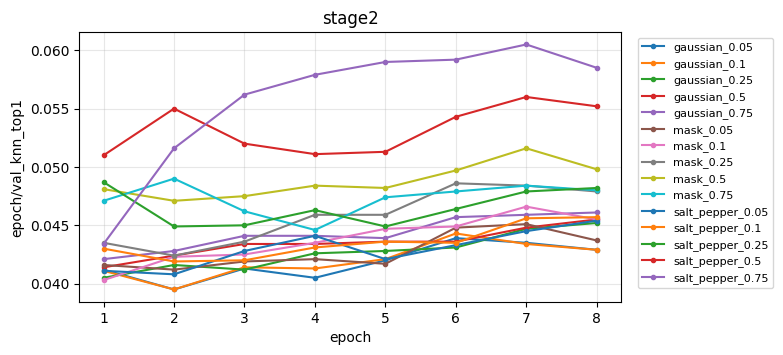

In [16]:
plot_metric("stage2")

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage2: the winner, by val k-NN top-1. It is saved in winners.json, and the next stage starts from it.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage2: המנצח, לפי val k-NN top-1. הוא נשמר ב-winners.json, והשלב הבא מתחיל ממנו.</p>
</div>

In [17]:
best_of("stage2")

  salt_pepper_0.75         val k-NN top-1 0.0605
  salt_pepper_0.5          val k-NN top-1 0.0560
  mask_0.5                 val k-NN top-1 0.0516
  mask_0.75                val k-NN top-1 0.0490
  salt_pepper_0.25         val k-NN top-1 0.0487
  mask_0.25                val k-NN top-1 0.0486
  mask_0.1                 val k-NN top-1 0.0466
  gaussian_0.75            val k-NN top-1 0.0461
  salt_pepper_0.1          val k-NN top-1 0.0457
  gaussian_0.5             val k-NN top-1 0.0455
  salt_pepper_0.05         val k-NN top-1 0.0454
  gaussian_0.25            val k-NN top-1 0.0452
  mask_0.05                val k-NN top-1 0.0451
  gaussian_0.1             val k-NN top-1 0.0443
  gaussian_0.05            val k-NN top-1 0.0439
winner of stage2: salt_pepper_0.75 (0.0605)


{'learning_rate': 0.001,
 'latent_dim': 64,
 'noise_type': 'salt_pepper',
 'noise_level': 0.75,
 'activation': 'gelu',
 'optimizer': 'adamw',
 'weight_decay': 0.01,
 'batch_size': 256}

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 3: latent_dim (5 runs)</p>
<ul>
<li>Starts from the stage-2 winner and tries latent_dim {32, 64, 128, 256, 512}, the length of h.</li>
<li>Version names: latent32 ... latent512.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 3: ‏latent_dim (‏5 ריצות)</p>
<ul>
<li>מתחיל מהמנצח של שלב 2 ובודק latent_dim {32, 64, 128, 256, 512}, האורך של h.</li>
<li>שמות הגרסאות: latent32 ... latent512.</li>
</ul>
</div>

In [18]:
start = load_winner("stage2")
for latent_dim in [32, 64, 128, 256, 512]:
    run_trial("stage3", f"latent{latent_dim}", {**start, "latent_dim": latent_dim})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  543 K │ train │     0 │
│ 1 │ decoder │ Sequential │  560 K │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 1.1 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.1 M                                                                                                
Total estimated model params size (MB): 4.415                                                                      
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (69 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage3/latent512: val k-NN top-1 0.0599 in 3.8 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage3: val k-NN top-1 per epoch, every run of the stage on one chart.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage3: ‏val k-NN top-1 לפי epoch, כל הריצות של השלב על גרף אחד.</p>
</div>

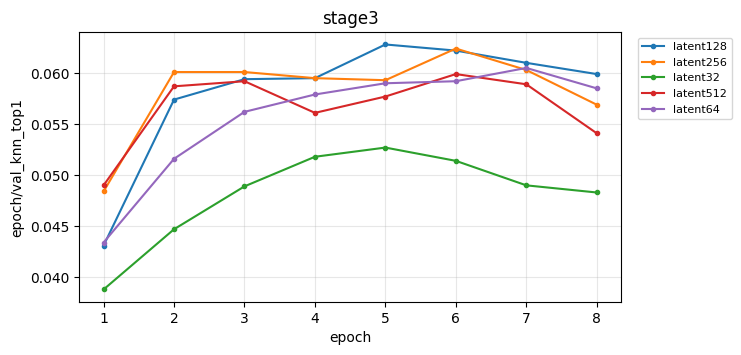

In [19]:
plot_metric("stage3")

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage3: the winner, by val k-NN top-1. It is saved in winners.json, and the next stage starts from it.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage3: המנצח, לפי val k-NN top-1. הוא נשמר ב-winners.json, והשלב הבא מתחיל ממנו.</p>
</div>

In [20]:
best_of("stage3")

  latent128                val k-NN top-1 0.0628
  latent256                val k-NN top-1 0.0624
  latent64                 val k-NN top-1 0.0605
  latent512                val k-NN top-1 0.0599
  latent32                 val k-NN top-1 0.0527
winner of stage3: latent128 (0.0628)


{'learning_rate': 0.001,
 'latent_dim': 128,
 'noise_type': 'salt_pepper',
 'noise_level': 0.75,
 'activation': 'gelu',
 'optimizer': 'adamw',
 'weight_decay': 0.01,
 'batch_size': 256}

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 4: batch size (4 runs)</p>
<ul>
<li>Starts from the stage-3 winner and tries batch size {64, 128, 256, 512}. get_dm builds one datamodule per batch size.</li>
<li>The learning rate stays the same, so a bigger batch also means fewer optimizer steps per epoch. Stage 5 tunes the learning rate after this.</li>
<li>Version names: bs64 ... bs512.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 4: ‏batch size (‏4 ריצות)</p>
<ul>
<li>מתחיל מהמנצח של שלב 3 ובודק batch size {64, 128, 256, 512}. ‏get_dm בונה datamodule אחד לכל batch size.</li>
<li>ה-learning rate נשאר אותו דבר, ולכן batch גדול יותר אומר גם פחות צעדי optimizer בכל epoch. שלב 5 מכוונן את ה-learning rate אחרי זה.</li>
<li>שמות הגרסאות: bs64 ... bs512.</li>
</ul>
</div>

In [21]:
start = load_winner("stage3")
for batch_size in [64, 128, 256, 512]:
    run_trial("stage4", f"bs{batch_size}", {**start, "batch_size": batch_size})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  2.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  2.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 4.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.2 M                                                                                                
Total estimated model params size (MB): 16.998                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (53 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage4/bs512: val k-NN top-1 0.0631 in 3.0 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage4: val k-NN top-1 per epoch, every run of the stage on one chart.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage4: ‏val k-NN top-1 לפי epoch, כל הריצות של השלב על גרף אחד.</p>
</div>

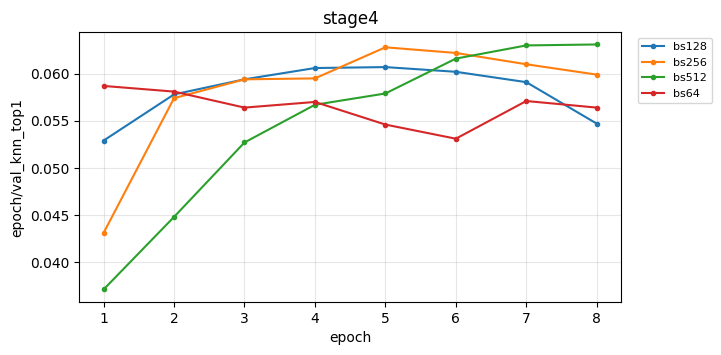

In [22]:
plot_metric("stage4")

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage4: the winner, by val k-NN top-1. It is saved in winners.json, and the next stage starts from it.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage4: המנצח, לפי val k-NN top-1. הוא נשמר ב-winners.json, והשלב הבא מתחיל ממנו.</p>
</div>

In [23]:
best_of("stage4")

  bs512                    val k-NN top-1 0.0631
  bs256                    val k-NN top-1 0.0628
  bs128                    val k-NN top-1 0.0607
  bs64                     val k-NN top-1 0.0587
winner of stage4: bs512 (0.0631)


{'learning_rate': 0.001,
 'latent_dim': 128,
 'noise_type': 'salt_pepper',
 'noise_level': 0.75,
 'activation': 'gelu',
 'optimizer': 'adamw',
 'weight_decay': 0.01,
 'batch_size': 512}

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 5: learning rate (5 runs)</p>
<ul>
<li>Starts from the stage-4 winner and tries lr {1e-4, 3e-4, 1e-3, 3e-3, 1e-2}.</li>
<li>Version names: lr1e-4 ... lr1e-2.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 5: ‏learning rate (‏5 ריצות)</p>
<ul>
<li>מתחיל מהמנצח של שלב 4 ובודק lr {1e-4, 3e-4, 1e-3, 3e-3, 1e-2}.</li>
<li>שמות הגרסאות: lr1e-4 ... lr1e-2.</li>
</ul>
</div>

In [24]:
start = load_winner("stage4")
for lr in ["1e-4", "3e-4", "1e-3", "3e-3", "1e-2"]:
    run_trial("stage5", f"lr{lr}", {**start, "learning_rate": float(lr)})

INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  2.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  2.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 4.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.2 M                                                                                                
Total estimated model params size (MB): 16.998                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (69 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage5/lr1e-2: val k-NN top-1 0.0459 in 3.0 min


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage5: val k-NN top-1 per epoch, every run of the stage on one chart.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage5: ‏val k-NN top-1 לפי epoch, כל הריצות של השלב על גרף אחד.</p>
</div>

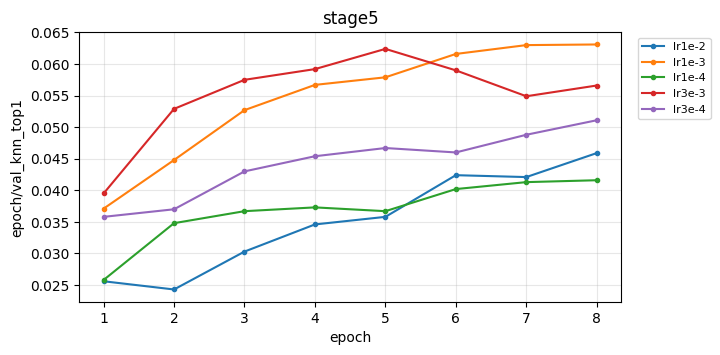

In [25]:
plot_metric("stage5")

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage5: the winner, by val k-NN top-1. It is saved in winners.json, and the next stage starts from it.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>stage5: המנצח, לפי val k-NN top-1. הוא נשמר ב-winners.json, והשלב הבא מתחיל ממנו.</p>
</div>

In [26]:
best_of("stage5")

  lr1e-3                   val k-NN top-1 0.0631
  lr3e-3                   val k-NN top-1 0.0624
  lr3e-4                   val k-NN top-1 0.0511
  lr1e-2                   val k-NN top-1 0.0459
  lr1e-4                   val k-NN top-1 0.0416
winner of stage5: lr1e-3 (0.0631)


{'learning_rate': 0.001,
 'latent_dim': 128,
 'noise_type': 'salt_pepper',
 'noise_level': 0.75,
 'activation': 'gelu',
 'optimizer': 'adamw',
 'weight_decay': 0.01,
 'batch_size': 512}

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 6: number of epochs (one 50-epoch run)</p>
<ul>
<li>One 50-epoch run of the stage-5 winner, still with the 20,000-image k-NN bank.</li>
<li>The learning rate is constant (no scheduler) and the seed is fixed, so the first N epochs of this run are the same as an N-epoch run. Reading val k-NN at epochs 5, 10, 20, 30 and 50 therefore compares five run lengths for the price of one run.</li>
<li>This is the longest cell. If Colab disconnects, run it again: it continues from last.ckpt.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 6: מספר ה-epochs (ריצה אחת של 50 epochs)</p>
<ul>
<li>ריצה אחת של 50 epochs של המנצח של שלב 5, עדיין עם bank של 20,000 תמונות ל-k-NN.</li>
<li>ה-learning rate קבוע (בלי scheduler) וה-seed קבוע, ולכן N ה-epochs הראשונים של הריצה הזאת זהים לריצה של N epochs. קריאה של val k-NN ב-epochs ‏5, 10, 20, 30 ו-50 משווה לכן חמישה אורכי ריצה במחיר של ריצה אחת.</li>
<li>זה התא הכי ארוך. אם Colab מתנתק, מריצים אותו שוב: הוא ממשיך מה-last.ckpt.</li>
</ul>
</div>

In [27]:
final_settings = load_winner("stage5")
print(final_settings)
run_trial("stage6", "winner_50ep", final_settings, epochs=50)

INFO:lightning_fabric.utilities.seed:Seed set to 42


{'learning_rate': 0.001, 'latent_dim': 128, 'noise_type': 'salt_pepper', 'noise_level': 0.75, 'activation': 'gelu', 'optimizer': 'adamw', 'weight_decay': 0.01, 'batch_size': 512}


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  2.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  2.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 4.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.2 M                                                                                                
Total estimated model params size (MB): 16.998                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (50 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

done stage6/winner_50ep: val k-NN top-1 0.0637 in 18.2 min


{'val_knn_top1': 0.06369999796152115,
 'epochs': 50,
 'minutes': 18.2,
 'settings': {'learning_rate': 0.001,
  'latent_dim': 128,
  'noise_type': 'salt_pepper',
  'noise_level': 0.75,
  'activation': 'gelu',
  'optimizer': 'adamw',
  'weight_decay': 0.01,
  'batch_size': 512}}

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Stage 6: val k-NN top-1 at epochs 5, 10, 20, 30 and 50, and the full curve.</p>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>שלב 6: ‏val k-NN top-1 ב-epochs ‏5, 10, 20, 30 ו-50, והעקומה המלאה.</p>
</div>

epoch  5: val k-NN top-1 0.0579
epoch 10: val k-NN top-1 0.0637
epoch 20: val k-NN top-1 0.0560
epoch 30: val k-NN top-1 0.0566
epoch 50: val k-NN top-1 0.0594


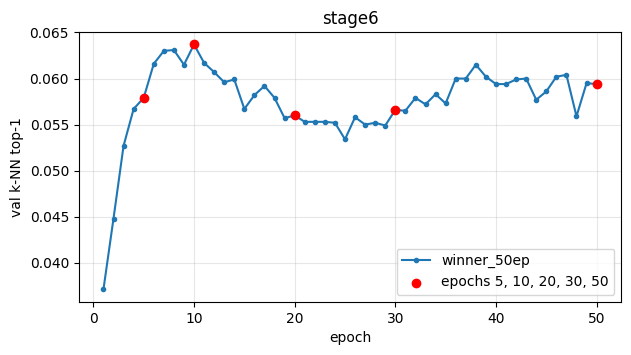

In [28]:
curve = dict(read_scalars("stage6", "winner_50ep"))  # step = epoch - 1
marks = [5, 10, 20, 30, 50]
for epoch in marks:
    print(f"epoch {epoch:>2}: val k-NN top-1 {curve[epoch - 1]:.4f}")

epochs = [step + 1 for step in sorted(curve)]
plt.figure(figsize=(7, 3.5))
plt.plot(epochs, [curve[e - 1] for e in epochs], marker=".", label="winner_50ep")
plt.scatter(marks, [curve[e - 1] for e in marks], color="red", zorder=3, label="epochs 5, 10, 20, 30, 50")
plt.xlabel("epoch")
plt.ylabel("val k-NN top-1")
plt.title("stage6")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Summary: reconstruction error vs. k-NN accuracy across all trials (the required plot of section A2)</p>
<ul>
<li>One point per run of stages 1 to 5, at the epoch with its best val k-NN top-1 (the epoch its checkpoint keeps).</li>
<li>x: val reconstruction loss (MSE) at that epoch. y: val k-NN top-1. Colors: the stage.</li>
<li>If better reconstruction meant a better representation, the points would fall from top left to bottom right.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>סיכום: שגיאת שחזור מול דיוק k-NN בכל הניסויים (הגרף שסעיף A2 דורש)</p>
<ul>
<li>נקודה אחת לכל ריצה בשלבים 1 עד 5, ב-epoch עם ה-val k-NN top-1 הכי טוב שלה (ה-epoch שה-checkpoint שלה שומר).</li>
<li>ציר x: ‏val reconstruction loss (‏MSE) ב-epoch הזה. ציר y: ‏val k-NN top-1. צבעים: השלב.</li>
<li>אם שחזור טוב יותר היה אומר ייצוג טוב יותר, הנקודות היו יורדות משמאל למעלה לימין למטה.</li>
</ul>
</div>

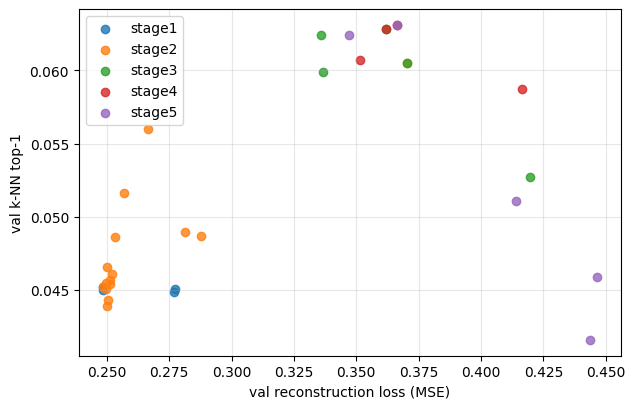

In [29]:
plt.figure(figsize=(7, 4.5))
for stage in ["stage1", "stage2", "stage3", "stage4", "stage5"]:
    xs, ys = [], []
    for version in finished_versions(stage):
        knn = dict(read_scalars(stage, version, "epoch/val_knn_top1"))
        loss = dict(read_scalars(stage, version, "epoch/val_loss"))
        if knn and loss:
            best_epoch = max(knn, key=knn.get)
            xs.append(loss[best_epoch])
            ys.append(knn[best_epoch])
    plt.scatter(xs, ys, label=stage, alpha=0.8)
plt.xlabel("val reconstruction loss (MSE)")
plt.ylabel("val k-NN top-1")
plt.legend()
plt.grid(alpha=0.3)
plt.show()